# 12 · Previsión de series temporales

Prever es predecir el futuro de una magnitud que se mide a lo largo del tiempo: la demanda eléctrica, las
ventas, el caudal de un río, el tráfico. No existe un único método mejor. Este notebook aplica siete técnicas,
desde una referencia de una línea hasta un Transformer, a **dos problemas elegidos para tener ganadores
opuestos**, y explica por qué cada una gana donde gana.

Ejecutar todos los modelos lleva unos 25 minutos en la CPU de un portátil (las redes neuronales se llevan la
mayor parte); los resultados guardados de abajo se pueden leer sin ejecutar nada.

**Aprenderás**
1. Las familias de métodos de previsión y cómo evaluarlos sin engañarte
2. Ingenuo estacional, SARIMA, Prophet, gradient boosting (XGBoost), una GRU en PyTorch, una LSTM en Keras y un Transformer, aplicados al mismo problema
3. **Ejemplo 1, demanda de bicicletas compartidas**: datos tabulares con variables conocidas y potentes, donde gana el gradient boosting
4. **Ejemplo 2, caudal de un río por la lluvia**: estado oculto y respuestas largas y suaves, donde ganan las redes neuronales recurrentes
5. Una guía de decisión para proyectos reales

## 1. El panorama

| Familia | Ejemplos | Aprende de | Destaca cuando |
|---|---|---|---|
| Referencias ingenuas | último valor, **ingenuo estacional** | nada | siempre es lo primero que hay que superar |
| Estadística clásica | ARIMA, **SARIMA**, ETS | el propio pasado de una serie | series cortas, estables y únicas; intervalos de incertidumbre |
| Descomponibles | **Prophet** | tendencia + estacionalidades + festivos + regresores | series de negocio con efectos de calendario claros, analistas que necesitan componentes interpretables |
| Aprendizaje automático sobre variables | **XGBoost**, LightGBM, bosques aleatorios | una tabla de variables construidas (retardos, calendario, covariables) | problemas tabulares con variables informativas y datos moderados; la mayoría de las competiciones |
| Redes recurrentes | **GRU**, **LSTM** | secuencias en bruto | memoria larga, estado oculto, muchas series relacionadas |
| Atención | **Transformers** (TFT, PatchTST, Informer) | secuencias en bruto, todas las posiciones a la vez (a menudo agrupadas en parches) | contextos largos, muchos datos |
| Modelos fundacionales | Chronos, TimesFM, Moirai | preentrenados con millones de series | previsiones sin entrenamiento previo (zero-shot) |

**Evaluar previsiones con honestidad**
- Divide por **tiempo**, nunca al azar: entrena con el pasado y prueba con el futuro.
- Usa **orígenes móviles**: prevé desde muchos puntos del periodo de prueba, como se usaría el modelo.
- Toda variable debe ser **conocida en el momento de prever**: la demanda de ayer sí, la demanda real de mañana
  no. El tiempo meteorológico del día siguiente viene de una previsión meteorológica; aquí usamos el tiempo
  observado en su lugar, una práctica habitual y ligeramente optimista para todos los modelos por igual.
- Informa siempre de una **referencia**: un modelo sofisticado que no supera al ingenuo estacional no sirve.

## 2. Ejemplo 1: demanda horaria de bicicletas compartidas
Dos años (2011-2012) de alquileres por hora de Capital Bikeshare, en Washington D.C., con el tiempo
meteorológico y el calendario: el conjunto *Bike Sharing* de UCI (Fanaee-T y Gama, 2013, licencia CC BY 4.0),
desde OpenML. La copia de OpenML no tiene la columna de fecha; las filas están en orden temporal, así que las
marcas de tiempo se reconstruyen a partir del año, el mes, el día de la semana y la hora, y se rellenan 165
horas que faltan (sin alquileres registrados).

**Tarea:** cada medianoche, prever los 24 recuentos horarios del día siguiente. Se entrena de enero de 2011 a
septiembre de 2012 y se prueba con los 92 días de octubre a diciembre de 2012.

In [1]:
import os, time, warnings, logging
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

raw = fetch_openml(data_id=42712, as_frame=True, parser="auto").frame
# a new day starts whenever the hour goes back down or the weekday changes
day, days, prev_h, prev_wd = 0, [], None, None
for h, wd in zip(raw["hour"].astype(int), raw["weekday"].astype(str)):
    if prev_h is not None and (h <= prev_h or wd != prev_wd):
        day += 1
    days.append(day); prev_h, prev_wd = h, wd
raw.index = pd.Timestamp("2011-01-01") + pd.to_timedelta(days, "D") + pd.to_timedelta(raw["hour"].astype(int), "h")
assert (raw.index.dayofweek == (raw["weekday"].astype(int) + 6) % 7).all()     # las fechas reconstruidas coinciden con los días de la semana

WEATHER = ["temp", "feel_temp", "humidity", "windspeed"]
bike = raw.reindex(pd.date_range(raw.index.min(), raw.index.max(), freq="h"))
bike["count"] = bike["count"].fillna(0)
for c in WEATHER + ["weather", "holiday", "workingday"]:
    bike[c] = bike[c].ffill()
bike = pd.DataFrame({
    "count": bike["count"].astype(float),
    **{c: bike[c].astype(float) for c in WEATHER},
    "weather": bike["weather"].astype(str).astype("category").cat.codes,
    "holiday": bike["holiday"].astype(str).isin(["True", "1"]).astype(int),
    "workingday": bike["workingday"].astype(str).isin(["True", "1"]).astype(int),
}, index=bike.index)
bike["hour"], bike["dow"], bike["month"] = bike.index.hour, bike.index.dayofweek, bike.index.month
print(bike.shape, bike.index.min(), "->", bike.index.max())
bike.head(3)

(17544, 11) 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


,count,temp,feel_temp,humidity,windspeed,weather,holiday,workingday,hour,dow,month
2011-01-01 00:00:00,16.0,9.84,14.395,0.81,0.0,0,0,0,0,5,1
2011-01-01 01:00:00,40.0,9.02,13.635,0.80,0.0,0,0,0,1,5,1
2011-01-01 02:00:00,32.0,9.02,13.635,0.80,0.0,0,0,0,2,5,1


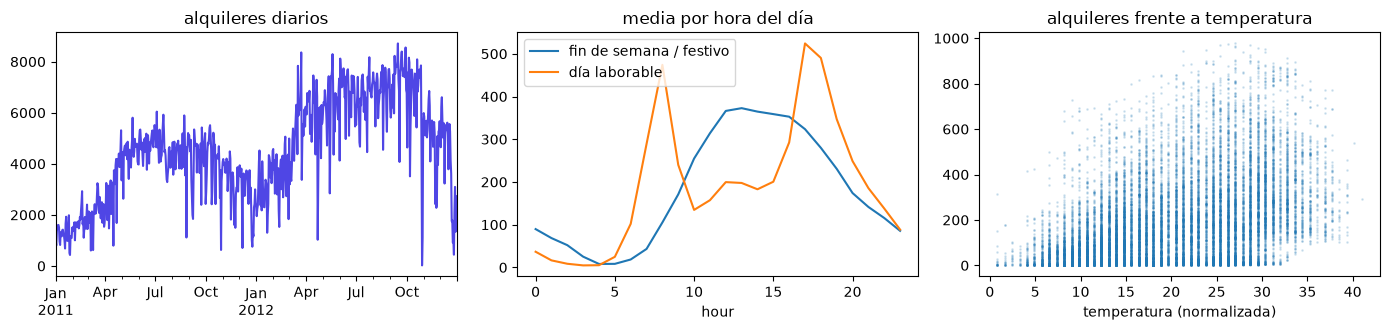

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
bike["count"].resample("D").sum().plot(ax=ax[0], title="alquileres diarios", color="#4f46e5")
for wd, g in bike.groupby("workingday"):
    g.groupby("hour")["count"].mean().plot(ax=ax[1], label="día laborable" if wd else "fin de semana / festivo")
ax[1].legend(); ax[1].set_title("media por hora del día")
ax[2].scatter(bike["temp"], bike["count"], s=1, alpha=.15); ax[2].set_xlabel("temperatura (normalizada)"); ax[2].set_title("alquileres frente a temperatura")
plt.tight_layout(); plt.show()

Los datos tienen todo lo que facilita prever con variables: dos patrones diarios fuertes (picos de ida y vuelta
al trabajo en días laborables, una joroba a mediodía en fines de semana), crecimiento de 2011 a 2012 y una
fuerte dependencia del tiempo. Modelamos `log(1 + count)` para que los errores de madrugada y de hora punta
cuenten en proporción, y puntuamos las previsiones en bicicletas por hora.

In [3]:
bike["y"] = np.log1p(bike["count"])
TEST_START = pd.Timestamp("2012-10-01")
test_days = pd.date_range(TEST_START, bike.index.max().normalize(), freq="D")
y_true = bike.loc[bike.index >= TEST_START, "count"].to_numpy()

results, forecasts = {}, {}
def score(name, pred_log, seconds):
    pred = np.clip(np.expm1(np.asarray(pred_log)), 0, None)
    forecasts[name] = pred
    results[name] = {"MAE (bicis/h)": np.mean(np.abs(pred - y_true)),
                     "RMSE (bicis/h)": np.sqrt(np.mean((pred - y_true) ** 2)),
                     "seconds": seconds}
    print(f"{name:<22} MAE {results[name]['MAE (bicis/h)']:6.1f}   RMSE {results[name]['RMSE (bicis/h)']:6.1f}   ({seconds:.0f} s)")
print(f"{len(test_days)} días de prueba, {len(y_true):,} horas")

92 días de prueba, 2,208 horas


### 2.1 Ingenuo estacional
Mañana a las 8:00 se parecerá al mismo día de la semana pasada a las 8:00. Una línea, sin ajuste.

In [4]:
t0 = time.perf_counter()
score("Ingenuo estacional (7 d)", bike["y"].shift(168).loc[bike.index >= TEST_START], time.perf_counter() - t0)

Ingenuo estacional (7 d) MAE   75.9   RMSE  129.8   (0 s)


### 2.2 SARIMA (statsmodels)
Un ARIMA estacional con una estación de 24 horas y el tiempo meteorológico como regresores externos (SARIMAX).
Ajustarlo con dos años de datos horarios es lento, así que se ajusta con las últimas ocho semanas antes del
periodo de prueba; cada medianoche se actualiza con el día real que acaba de terminar (sin reajustar) y prevé
las 24 horas siguientes.

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
EXOG = ["temp", "humidity", "windspeed", "workingday"]
t0 = time.perf_counter()
hist = bike.loc[TEST_START - pd.Timedelta(weeks=8): TEST_START - pd.Timedelta(hours=1)]
res = SARIMAX(hist["y"], exog=hist[EXOG], order=(2, 0, 1), seasonal_order=(1, 0, 1, 24),
              enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=60)
preds = []
for i, d in enumerate(test_days):
    day = bike.loc[d: d + pd.Timedelta(hours=23)]
    if i > 0:
        prev = bike.loc[d - pd.Timedelta(days=1): d - pd.Timedelta(hours=1)]
        res = res.append(prev["y"], exog=prev[EXOG], refit=False)
    preds.append(res.forecast(len(day), exog=day[EXOG]).to_numpy())
score("SARIMA", np.concatenate(preds), time.perf_counter() - t0)

/home/patito/Developments/academy/python/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SARIMA                 MAE   94.3   RMSE  140.6   (50 s)


### 2.3 Prophet
Prophet, de Meta, modela una serie como tendencia + estacionalidad anual, semanal y diaria + regresores, y se
ajusta una sola vez. No mira los valores de los últimos días, así que no puede reaccionar a una sorpresa
reciente, pero sus componentes son fáciles de explicar a personas no especialistas.

In [6]:
from prophet import Prophet
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").setLevel(logging.ERROR)
train = bike.loc[bike.index < TEST_START]
t0 = time.perf_counter()
pdf = pd.DataFrame({"ds": train.index, "y": train["y"].to_numpy(), **{c: train[c].to_numpy() for c in EXOG}})
prophet = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
for c in EXOG:
    prophet.add_regressor(c)
prophet.fit(pdf)
test = bike.loc[bike.index >= TEST_START]
fut = pd.DataFrame({"ds": test.index, **{c: test[c].to_numpy() for c in EXOG}})
score("Prophet", prophet.predict(fut)["yhat"].to_numpy(), time.perf_counter() - t0)

Importing plotly failed. Interactive plots will not work.


Prophet                MAE   84.9   RMSE  125.4   (9 s)


### 2.4 Gradient boosting (XGBoost)
Convertir la previsión en una tabla: una fila por hora, con variables de calendario, el tiempo meteorológico y
**retardos conocidos a medianoche**: la misma hora de ayer (24 h), de hace dos días (48 h) y de la semana pasada
(168 h), y la media de ayer. Un solo modelo prevé directamente cada hora del día.

In [7]:
import xgboost as xgb
feat = bike.copy()
feat["lag24"], feat["lag48"], feat["lag168"] = feat["y"].shift(24), feat["y"].shift(48), feat["y"].shift(168)
feat["prev_day_mean"] = feat["y"].shift(24).rolling(24).mean()     # termina como muy tarde en la medianoche de la previsión
feat["trend"] = np.arange(len(feat))
FEATURES = ["hour", "dow", "month", "workingday", "holiday", "weather", *WEATHER,
            "lag24", "lag48", "lag168", "prev_day_mean", "trend"]
tr_rows = feat.loc[feat.index < TEST_START].dropna()
te_rows = feat.loc[feat.index >= TEST_START]

t0 = time.perf_counter()
xgb_model = xgb.XGBRegressor(n_estimators=800, max_depth=7, learning_rate=0.03, subsample=0.8,
                             colsample_bytree=0.8, n_jobs=4, random_state=0)
xgb_model.fit(tr_rows[FEATURES], tr_rows["y"])
score("XGBoost", xgb_model.predict(te_rows[FEATURES]), time.perf_counter() - t0)

XGBoost                MAE   44.6   RMSE   71.0   (4 s)


### 2.5 Redes neuronales: GRU (PyTorch), LSTM (Keras), Transformer (PyTorch)
Los modelos de secuencias reciben el historial en bruto en lugar de retardos hechos a mano: los últimos **7 días**
(168 horas) de demanda, tiempo y calendario, más el tiempo y el calendario de las **24 horas a prever**, y
devuelven los 24 valores a la vez. El entrenamiento usa como origen de previsión una de cada tres horas del
periodo de entrenamiento (unos 5.000 ejemplos); las cuatro últimas semanas de entrenamiento se reservan para
detenerlo en la mejor época.

In [8]:
SEQ_IN = ["y", "temp", "humidity", "windspeed", "workingday", "holiday"]
FUT_IN = ["temp", "humidity", "windspeed", "workingday", "holiday"]
L, H = 168, 24
arr = bike.assign(h_sin=np.sin(2 * np.pi * bike["hour"] / 24), h_cos=np.cos(2 * np.pi * bike["hour"] / 24),
                  d_sin=np.sin(2 * np.pi * bike["dow"] / 7), d_cos=np.cos(2 * np.pi * bike["dow"] / 7))
CAL = ["h_sin", "h_cos", "d_sin", "d_cos"]
past = arr[SEQ_IN + CAL].to_numpy(np.float32)
future = arr[FUT_IN + CAL].to_numpy(np.float32)
target = arr["y"].to_numpy(np.float32)
mu, sd = past[: arr.index.get_loc(TEST_START)].mean(0), past[: arr.index.get_loc(TEST_START)].std(0) + 1e-6
fmu, fsd = future[: arr.index.get_loc(TEST_START)].mean(0), future[: arr.index.get_loc(TEST_START)].std(0) + 1e-6
past_n, fut_n = (past - mu) / sd, (future - fmu) / fsd
y_mu, y_sd = mu[0], sd[0]

def make(origins):
    X = np.stack([past_n[o - L:o] for o in origins])
    F = np.stack([fut_n[o:o + H] for o in origins])
    Y = np.stack([(target[o:o + H] - y_mu) / y_sd for o in origins])
    return X, F, Y

test_o = [arr.index.get_loc(d) for d in test_days]
val_start = arr.index.get_loc(TEST_START - pd.Timedelta(weeks=4))
train_o = list(range(L, val_start - H, 3))
val_o = [arr.index.get_loc(d) for d in pd.date_range(TEST_START - pd.Timedelta(weeks=4), TEST_START - pd.Timedelta(days=1), freq="D")]
(Xtr, Ftr, Ytr), (Xva, Fva, Yva), (Xte, Fte, _) = make(train_o), make(val_o), make(test_o)
print("entrenamiento", Xtr.shape, "validación", Xva.shape, "prueba", Xte.shape)
to_log = lambda p: p.reshape(-1) * y_sd + y_mu

entrenamiento (4824, 168, 10) validación (28, 168, 10) prueba (92, 168, 10)


In [9]:
import torch
torch.manual_seed(0); torch.set_num_threads(4)

def train_torch(model, epochs=30, lr=2e-3, batch=128, patience=5):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    t = lambda a: torch.tensor(a)
    Xt, Ft, Yt, Xv, Fv, Yv = map(t, (Xtr, Ftr, Ytr, Xva, Fva, Yva))
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        for i in torch.randperm(len(Xt)).split(batch):
            opt.zero_grad()
            loss = torch.nn.functional.mse_loss(model(Xt[i], Ft[i]), Yt[i]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = torch.nn.functional.mse_loss(model(Xv, Fv), Yv).item()
        if v < best - 1e-4:
            best, best_state, bad = v, {k: x.clone() for k, x in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        return model(torch.tensor(Xte), torch.tensor(Fte)).numpy(), ep + 1

class GRUForecaster(torch.nn.Module):
    '''La GRU codificadora lee la semana pasada; una red pequeña combina su estado final con las covariables del día siguiente.'''
    def __init__(self, n_in, n_fut, hidden=64):
        super().__init__()
        self.gru = torch.nn.GRU(n_in, hidden, batch_first=True)
        self.head = torch.nn.Sequential(torch.nn.Linear(hidden + n_fut * H, 128), torch.nn.ReLU(), torch.nn.Linear(128, H))
    def forward(self, x, f):
        _, h = self.gru(x)
        return self.head(torch.cat([h[-1], f.flatten(1)], 1))

t0 = time.perf_counter()
p, ep = train_torch(GRUForecaster(Xtr.shape[2], Ftr.shape[2]))
score("GRU (PyTorch)", to_log(p), time.perf_counter() - t0); print(f"   detenido tras {ep} épocas")

GRU (PyTorch)          MAE   46.4   RMSE   75.0   (250 s)
   detenido tras 18 épocas


In [10]:
import tensorflow as tf
tf.keras.utils.set_random_seed(0)
inp_x = tf.keras.Input((L, Xtr.shape[2])); inp_f = tf.keras.Input((H, Ftr.shape[2]))
z = tf.keras.layers.LSTM(64)(inp_x)
z = tf.keras.layers.Concatenate()([z, tf.keras.layers.Flatten()(inp_f)])
z = tf.keras.layers.Dense(128, activation="relu")(z)
lstm = tf.keras.Model([inp_x, inp_f], tf.keras.layers.Dense(H)(z))
lstm.compile(optimizer=tf.keras.optimizers.Adam(2e-3), loss="mse")
t0 = time.perf_counter()
hist_k = lstm.fit([Xtr, Ftr], Ytr, validation_data=([Xva, Fva], Yva), epochs=30, batch_size=128, verbose=0,
                  callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
score("LSTM (Keras)", to_log(lstm.predict([Xte, Fte], verbose=0)), time.perf_counter() - t0)
print(f"   detenido tras {len(hist_k.history['loss'])} épocas")

I0000 00:00:1792319299.854917 1040962 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792319303.250631 1040962 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


LSTM (Keras)           MAE   50.0   RMSE   81.4   (239 s)
   detenido tras 22 épocas


In [11]:
class PatchTransformer(torch.nn.Module):
    '''Al estilo de PatchTST: la semana se corta en 7 parches de 24 horas, cada parche se convierte en un token, y
    la autoatención relaciona cada día de la semana con todos los demás. 7 tokens en lugar de 168 abaratan mucho
    la atención, y así manejan las entradas largas los Transformers de previsión modernos.'''
    def __init__(self, n_in, n_fut, d=64, heads=4, layers=2, patch=24):
        super().__init__()
        self.patch = patch
        self.embed = torch.nn.Linear(n_in * patch, d)
        self.pos = torch.nn.Parameter(torch.randn(1, L // patch, d) * 0.02)          # posición aprendida por día
        layer = torch.nn.TransformerEncoderLayer(d, heads, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.encoder = torch.nn.TransformerEncoder(layer, layers)
        self.head = torch.nn.Sequential(torch.nn.Linear(d * (L // patch) + n_fut * H, 128), torch.nn.ReLU(), torch.nn.Linear(128, H))
    def forward(self, x, f):
        tokens = x.reshape(x.shape[0], L // self.patch, -1)                          # (lote, 7 días, 24 h x variables)
        z = self.encoder(self.embed(tokens) + self.pos)
        return self.head(torch.cat([z.flatten(1), f.flatten(1)], 1))

torch.manual_seed(0)
t0 = time.perf_counter()
p, ep = train_torch(PatchTransformer(Xtr.shape[2], Ftr.shape[2]), lr=1e-3)
score("Transformer (PyTorch)", to_log(p), time.perf_counter() - t0); print(f"   detenido tras {ep} épocas")

Transformer (PyTorch)  MAE   50.0   RMSE   83.0   (121 s)
   detenido tras 17 épocas


### 2.6 Resultados

,MAE (bicis/h),RMSE (bicis/h),seconds
XGBoost,44.6,71.0,3.7
GRU (PyTorch),46.4,75.0,250.4
LSTM (Keras),50.0,81.4,239.1
Transformer (PyTorch),50.0,83.0,121.5
Ingenuo estacional (7 d),75.9,129.8,0.0
Prophet,84.9,125.4,8.9
SARIMA,94.3,140.6,50.2


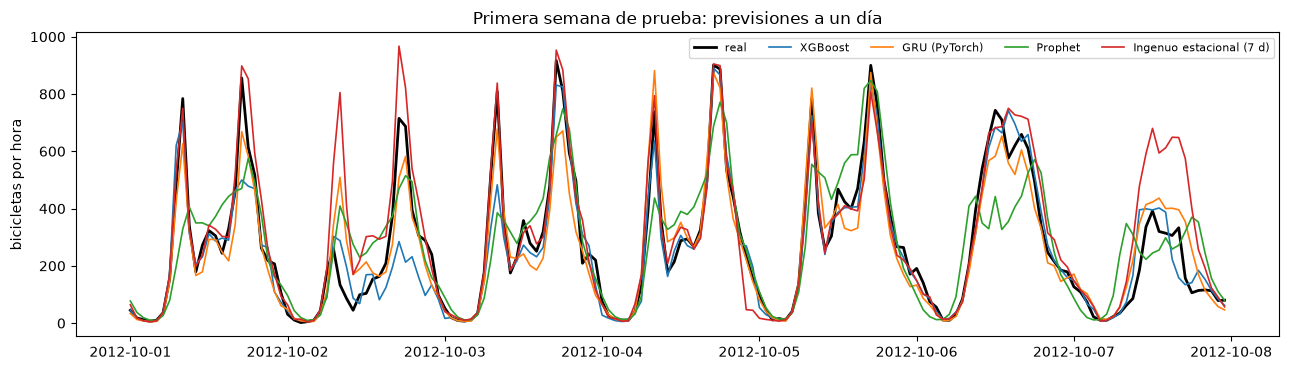

In [12]:
table_a = pd.DataFrame(results).T.sort_values("MAE (bicis/h)").round(1)
display(table_a)

week = slice(0, 24 * 7)
idx = bike.index[bike.index >= TEST_START][week]
plt.figure(figsize=(13, 3.8))
plt.plot(idx, y_true[week], color="black", lw=2, label="real")
for name in ["XGBoost", "GRU (PyTorch)", "Prophet", "Ingenuo estacional (7 d)"]:
    plt.plot(idx, forecasts[name][week], lw=1.2, label=name)
plt.legend(ncol=5, fontsize=8); plt.title("Primera semana de prueba: previsiones a un día"); plt.ylabel("bicicletas por hora")
plt.tight_layout(); plt.show()

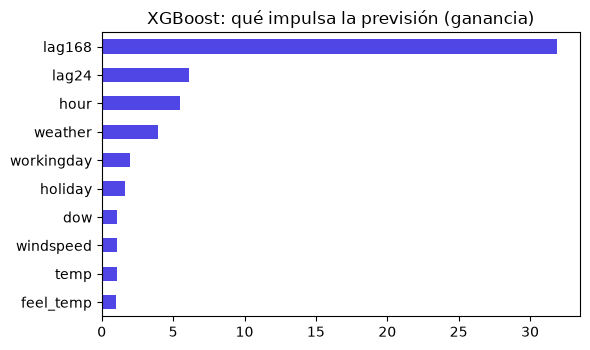

In [13]:
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="gain")).sort_values()
imp.tail(10).plot.barh(figsize=(6, 3.6), color="#4f46e5", title="XGBoost: qué impulsa la previsión (ganancia)")
plt.tight_layout(); plt.show()

### Por qué gana aquí el gradient boosting
**XGBoost tiene el menor error** (unas 45 bicicletas por hora frente a 76 del ingenuo estacional) y se entrena en
segundos. La GRU se queda cerca, a pocos puntos porcentuales, tras minutos de entrenamiento; la LSTM y el
Transformer quedan algo más atrás. SARIMA y Prophet lo hacen peor que la referencia de una línea: la estructura
lineal de SARIMA, ajustada con las semanas recientes, no puede representar el cambio entre el patrón laborable y
el de fin de semana ni el efecto no lineal del tiempo, y Prophet nunca mira los últimos días, así que no puede
ajustarse al nivel actual de demanda.

Lo que convierte esto en un problema de gradient boosting:
1. **La información está en unas pocas variables fuertes y conocidas.** La hora, el día laborable y el tiempo
   deciden la mayor parte de la demanda, y todas se conocen al hacer la previsión. Un modelo que traduce
   variables en demanda no necesita más memoria del pasado que unos pocos retardos.
2. **Interacciones bruscas.** "Hora punta, pero solo en días laborables" y "la lluvia hunde la demanda" son
   exactamente las divisiones si-entonces de las que están hechos los árboles; una red neuronal tiene que
   aproximarlas con funciones suaves.
3. **Pocos datos.** 21 meses de una sola ciudad son unas 5.000 ventanas de entrenamiento: de sobra para los
   árboles, modesto para redes con decenas de miles de pesos.
4. **Entradas mezcladas.** Las categorías, los indicadores binarios y los valores continuos de escalas distintas
   no necesitan escalado ni embeddings en los árboles.
5. **Coste y claridad.** Segundos en lugar de minutos, y un gráfico de importancia de variables que explica el modelo.

Las redes no fueron inútiles: a partir de la semana de historial en bruto redescubrieron la mayor parte de la
estructura que los retardos le daban gratis a XGBoost. Con muchos más datos (muchas ciudades, muchos años) esa
ventaja crece.

## 3. Ejemplo 2: el caudal de un río impulsado por la lluvia
Los hidrólogos prevén el caudal de los ríos para avisar de inundaciones. El caudal en una estación de aforo
depende de la lluvia caída en la cuenca, pero no de forma sencilla: la lluvia primero empapa el suelo, y solo un
suelo húmedo produce escorrentía; después el agua llega al río en horas o días por caminos lentos y rápidos, con
un retardo y una forma propios de cada cuenca. La humedad del suelo es un **estado oculto** que nunca se mide
directamente.

Simulamos **24 cuencas** con un modelo conceptual estándar (un depósito de suelo con un umbral de escorrentía no
lineal, depósitos rápido y lento y un retardo de tránsito propio de cada cuenca), cada una con sus parámetros
desconocidos, así que el comportamiento real se conoce y no hay problemas de licencias. En grandes conjuntos de
datos reales de este tipo (por ejemplo CAMELS, 671 cuencas de Estados Unidos) las LSTM han superado tanto a los
modelos hidrológicos conceptuales como a los conjuntos de árboles, y este ejemplo lo reproduce en miniatura.

**Tarea:** en cada origen de previsión, con las últimas 72 horas de lluvia y caudal y la **previsión de lluvia de
las 48 horas siguientes**, predecir el caudal de esas 48 horas. Un solo modelo para todas las cuencas, sin decirle
qué cuenca está viendo: tiene que reconocer el comportamiento de la cuenca a partir del historial.

### 3.1 Simular las cuencas

simuladas 24 cuencas x 17,520 horas en 3 s


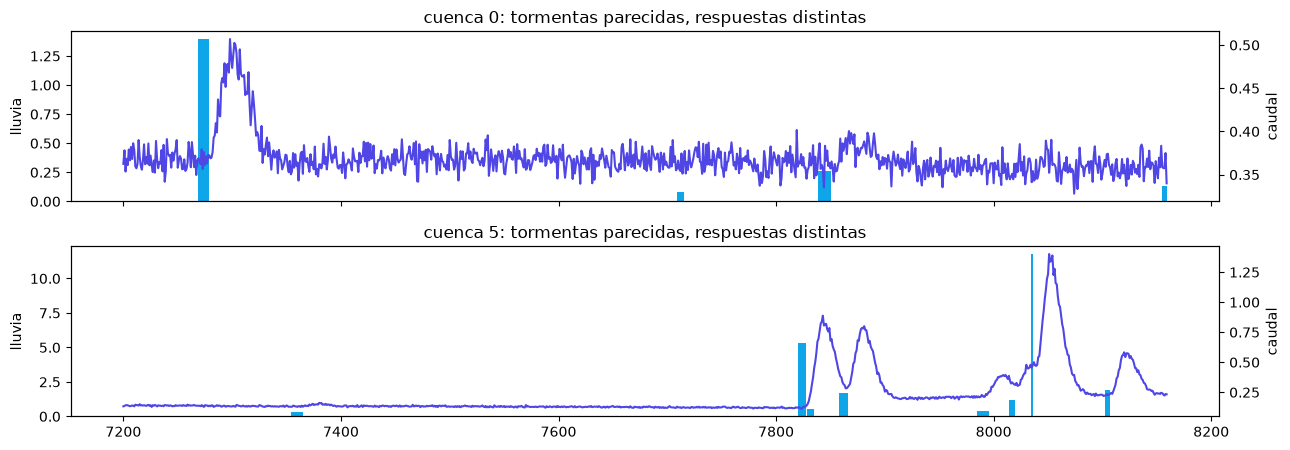

In [14]:
rng = np.random.default_rng(0)
HOURS = 24 * 365 * 2                                  # dos años por cuenca: el año 1 para entrenar, el año 2 para probar

def simulate_catchment(p, rng):
    t = np.arange(HOURS)
    season = 1 + 0.6 * np.sin(2 * np.pi * t / (24 * 365))
    rain = np.zeros(HOURS)
    for s in np.where(rng.random(HOURS) < 0.015 * season)[0]:          # tormentas: comienzos aleatorios, más en invierno
        dur = rng.integers(2, 14)
        rain[s:s + dur] += rng.gamma(1.4, 7) / dur
    S, fast, slow, q = p["Smax"] * 0.4, 0.0, 0.0, np.zeros(HOURS)
    pet = 0.06 * (1 + 0.8 * np.sin(2 * np.pi * (t - 24 * 80) / (24 * 365)))   # evaporación, mayor en verano
    for i in range(HOURS):
        runoff = rain[i] * (S / p["Smax"]) ** p["b"]                    # suelo húmedo -> más lluvia se convierte en escorrentía
        S = max(0.0, min(p["Smax"], S + rain[i] - runoff) - pet[i] * S / p["Smax"])
        fast += runoff; slow += 0.004 * S                               # camino superficial rápido, camino subterráneo lento
        out = p["kf"] * fast + p["ks"] * slow
        fast -= p["kf"] * fast; slow -= p["ks"] * slow
        q[i] = out
    k = np.arange(48)
    uh = k ** (p["shape"] - 1) * np.exp(-k / p["scale"]); uh /= uh.sum()   # retardo de tránsito, propio de cada cuenca
    flow = np.convolve(q, uh)[:HOURS]
    return rain, flow * (1 + 0.03 * rng.standard_normal(HOURS))       # 3% de ruido de medida

t0 = time.perf_counter()
catchments = []
for c in range(24):
    p = dict(Smax=rng.uniform(40, 220), b=rng.uniform(1.5, 4.5), kf=rng.uniform(0.1, 0.4),
             ks=rng.uniform(0.004, 0.02), shape=rng.uniform(1.5, 6), scale=rng.uniform(1.5, 5))
    catchments.append(simulate_catchment(p, rng))
print(f"simuladas {len(catchments)} cuencas x {HOURS:,} horas en {time.perf_counter() - t0:.0f} s")

fig, axes = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
for ax, c in zip(axes, [0, 5]):
    rain, flow = catchments[c]
    sl = slice(24 * 300, 24 * 340)
    ax.bar(np.arange(sl.start, sl.stop), rain[sl], color="#0ea5e9", width=1, label="lluvia")
    ax2 = ax.twinx(); ax2.plot(np.arange(sl.start, sl.stop), flow[sl], color="#4f46e5", label="caudal del río")
    ax.set_ylabel("lluvia"); ax2.set_ylabel("caudal"); ax.set_title(f"cuenca {c}: tormentas parecidas, respuestas distintas")
plt.tight_layout(); plt.show()

Fíjate en lo distinto que responden las dos cuencas a tormentas parecidas: el tamaño de la respuesta depende de lo
húmedo que ya estaba el suelo, y el retardo y la forma de la crecida dependen de la cuenca.

In [15]:
L2, H2 = 72, 48
def windows(rain, flow, start, end, stride):
    X, R, Y = [], [], []
    for o in range(max(start, L2), end - H2, stride):
        X.append(np.stack([rain[o - L2:o], flow[o - L2:o]], 1)); R.append(rain[o:o + H2]); Y.append(flow[o:o + H2])
    return np.array(X, np.float32), np.array(R, np.float32), np.array(Y, np.float32)

YEAR = 24 * 365
tr = [windows(r, f, 0, YEAR - 24 * 30, 16) for r, f in catchments]             # entrenamiento, se reserva el último mes
va = [windows(r, f, YEAR - 24 * 30, YEAR, 24) for r, f in catchments]          # validación para la parada temprana
te = [windows(r, f, YEAR, HOURS, 24) for r, f in catchments]                    # una previsión al día en el año 2
stack = lambda parts, k: np.concatenate([p[k] for p in parts])
Xtr2, Rtr2, Ytr2 = (stack(tr, k) for k in range(3))
Xva2, Rva2, Yva2 = (stack(va, k) for k in range(3))
Xte2, Rte2, Yte2 = (stack(te, k) for k in range(3))
print("entrenamiento", Xtr2.shape, "validación", Xva2.shape, "prueba", Xte2.shape)

results2, preds2 = {}, {}
def score2(name, pred, seconds):
    preds2[name] = pred
    results2[name] = {"MAE": float(np.mean(np.abs(pred - Yte2))), "RMSE": float(np.sqrt(np.mean((pred - Yte2) ** 2))),
                      "MAE caudales altos": float(np.mean(np.abs(pred - Yte2)[Yte2 > np.quantile(Yte2, 0.95)])), "seconds": seconds}
    r = results2[name]
    print(f"{name:<34} MAE {r['MAE']:.4f}  RMSE {r['RMSE']:.4f}  MAE 5% caudales más altos {r['MAE caudales altos']:.4f}  ({seconds:.0f} s)")

score2("Persistencia (último caudal)", np.repeat(Xte2[:, -1:, 1], H2, 1), 0)

entrenamiento (11880, 72, 2) validación (672, 72, 2) prueba (8712, 72, 2)
Persistencia (último caudal)       MAE 0.1186  RMSE 0.2649  MAE 5% caudales más altos 0.6219  (0 s)


El ingenuo estacional, SARIMA y Prophet se dejan fuera a propósito: el caudal de un río no tiene un ciclo diario
o semanal fiable, y su motor (la lluvia) actúa a través de una respuesta no lineal y dependiente del estado que
esos modelos no pueden expresar. La persistencia es la referencia honesta.

### 3.2 Gradient boosting con las mejores variables que podemos darle
La misma receta que ganó el ejemplo 1: una tabla con el caudal y la lluvia recientes, los totales de la ventana y
la lluvia prevista para cada una de las 48 horas siguientes con su total acumulado. Un solo modelo para todos los
horizontes, con el horizonte como variable.

In [16]:
def table(X, R):
    rain, flow = X[:, :, 0], X[:, :, 1]
    base = np.concatenate([flow[:, -24:], rain[:, -24:], rain.sum(1, keepdims=True), flow.mean(1, keepdims=True),
                           flow.max(1, keepdims=True), R, np.cumsum(R, 1)], 1)
    n = len(base)
    lead = np.tile(np.arange(H2), n)[:, None]
    return np.concatenate([np.repeat(base, H2, 0), lead], 1).astype(np.float32)

t0 = time.perf_counter()
gbm2 = xgb.XGBRegressor(n_estimators=500, max_depth=8, learning_rate=0.05, subsample=0.5, colsample_bytree=0.8,
                        tree_method="hist", n_jobs=4, random_state=0)
gbm2.fit(table(Xtr2, Rtr2), Ytr2.reshape(-1))
score2("XGBoost (variables construidas)", gbm2.predict(table(Xte2, Rte2)).reshape(-1, H2), time.perf_counter() - t0)

XGBoost (variables construidas)    MAE 0.0561  RMSE 0.1228  MAE 5% caudales más altos 0.2991  (775 s)


### 3.3 Redes recurrentes: GRU (PyTorch) y LSTM (Keras) codificador-decodificador
Un **codificador** lee las 72 horas pasadas de lluvia y caudal; su estado oculto final es la estimación propia de
la red sobre el estado de la cuenca (lo húmeda que está, lo rápido que responde). Después un **decodificador**
recorre las 48 horas de previsión, leyendo la lluvia prevista hora a hora y actualizando ese estado, tal como el
agua se mueve por la cuenca. No se construye ninguna variable a mano.

In [17]:
r_sd, f_sd = Xtr2[:, :, 0].std(), Ytr2.std()
def norm(X, R):
    return np.concatenate([X[:, :, :1] / r_sd, X[:, :, 1:] / f_sd], 2).astype(np.float32), (R / r_sd)[..., None].astype(np.float32)
(Xtr_n, Rtr_n), (Xva_n, Rva_n), (Xte_n, Rte_n) = norm(Xtr2, Rtr2), norm(Xva2, Rva2), norm(Xte2, Rte2)

class Seq2SeqGRU(torch.nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.encoder = torch.nn.GRU(2, hidden, batch_first=True)
        self.decoder = torch.nn.GRU(1, hidden, batch_first=True)
        self.out = torch.nn.Linear(hidden, 1)
    def forward(self, x, r):
        _, state = self.encoder(x)                 # el "estado de la cuenca" aprendido
        y, _ = self.decoder(r, state)              # llevado hacia delante a través de la lluvia prevista
        return self.out(y).squeeze(-1)

torch.manual_seed(0)
net = Seq2SeqGRU(); opt = torch.optim.Adam(net.parameters(), lr=2e-3)
T = lambda a: torch.tensor(a)
xt, rt, yt = T(Xtr_n), T(Rtr_n), T(Ytr2 / f_sd)
xv, rv, yv = T(Xva_n), T(Rva_n), T(Yva2 / f_sd)
best, best_state, bad, t0 = np.inf, None, 0, time.perf_counter()
for ep in range(30):
    net.train()
    for i in torch.randperm(len(xt)).split(128):
        opt.zero_grad(); loss = torch.nn.functional.l1_loss(net(xt[i], rt[i]), yt[i]); loss.backward(); opt.step()
    net.eval()
    with torch.no_grad():
        v = torch.nn.functional.l1_loss(net(xv, rv), yv).item()
    if v < best:
        best, best_state, bad = v, {k: x.clone() for k, x in net.state_dict().items()}, 0
    else:
        bad += 1
        if bad >= 6:
            break
net.load_state_dict(best_state); net.eval()
with torch.no_grad():
    p = net(T(Xte_n), T(Rte_n)).numpy() * f_sd
score2("GRU codificador-decodificador (PyTorch)", p, time.perf_counter() - t0); print(f"   {ep + 1} épocas")

GRU codificador-decodificador (PyTorch) MAE 0.0342  RMSE 0.0816  MAE 5% caudales más altos 0.1799  (1821 s)
   30 épocas


In [18]:
tf.keras.utils.set_random_seed(0)
enc_in = tf.keras.Input((L2, 2)); dec_in = tf.keras.Input((H2, 1))
_, h, c = tf.keras.layers.LSTM(64, return_state=True)(enc_in)
dec = tf.keras.layers.LSTM(64, return_sequences=True)(dec_in, initial_state=[h, c])
lstm2 = tf.keras.Model([enc_in, dec_in], tf.keras.layers.Dense(1)(dec))
lstm2.compile(optimizer=tf.keras.optimizers.Adam(2e-3), loss="mae")
t0 = time.perf_counter()
h2 = lstm2.fit([Xtr_n, Rtr_n], (Ytr2 / f_sd)[..., None], validation_data=([Xva_n, Rva_n], (Yva2 / f_sd)[..., None]),
               epochs=30, batch_size=128, verbose=0,
               callbacks=[tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
score2("LSTM codificador-decodificador (Keras)", lstm2.predict([Xte_n, Rte_n], verbose=0)[..., 0] * f_sd, time.perf_counter() - t0)
print(f"   {len(h2.history['loss'])} épocas")

LSTM codificador-decodificador (Keras) MAE 0.0379  RMSE 0.0915  MAE 5% caudales más altos 0.2097  (768 s)
   23 épocas


### 3.4 Resultados

,MAE,RMSE,MAE caudales altos,seconds
GRU codificador-decodificador (PyTorch),0.0342,0.0816,0.1799,1821.2151
LSTM codificador-decodificador (Keras),0.0379,0.0915,0.2097,767.5537
XGBoost (variables construidas),0.0561,0.1228,0.2991,774.8937
Persistencia (último caudal),0.1186,0.2649,0.6219,0.0000


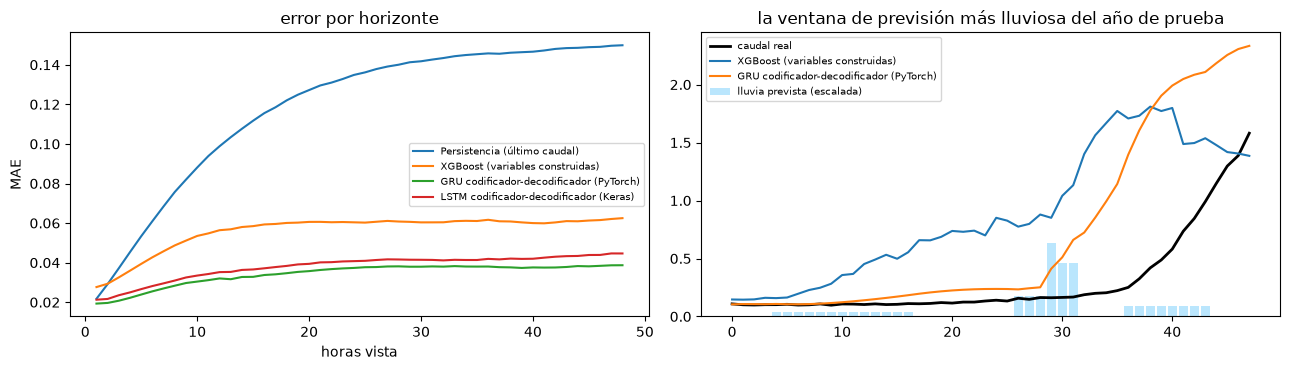

In [19]:
table_b = pd.DataFrame(results2).T.sort_values("MAE").round(4)
display(table_b)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for name in preds2:
    ax[0].plot(range(1, H2 + 1), np.mean(np.abs(preds2[name] - Yte2), 0), label=name)
ax[0].set_xlabel("horas vista"); ax[0].set_ylabel("MAE"); ax[0].set_title("error por horizonte"); ax[0].legend(fontsize=7)
i = int(np.argmax(Rte2.sum(1)))                                   # la ventana de previsión con más lluvia
ax[1].bar(range(H2), Rte2[i] / Rte2[i].max() * Yte2[i].max() * 0.4, color="#bae6fd", label="lluvia prevista (escalada)")
ax[1].plot(Yte2[i], color="black", lw=2, label="caudal real")
for name in ["XGBoost (variables construidas)", "GRU codificador-decodificador (PyTorch)"]:
    ax[1].plot(preds2[name][i], label=name)
ax[1].set_title("la ventana de previsión más lluviosa del año de prueba"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Por qué ganan aquí las redes recurrentes
**La GRU reduce el error en torno a un 40% respecto a XGBoost**, y en un margen parecido en el 5% de caudales más
altos, las crecidas para las que existe un servicio de alerta. La LSTM le sigue de cerca. El gráfico de error por
horizonte muestra dónde: la diferencia se abre desde la primera hora y crece hasta unas 12 horas vista, a medida
que la previsión depende cada vez más de cómo convierte la cuenca la lluvia futura en caudal, y después se
mantiene más o menos constante.

Cada tormenta es distinta, y la ventana más lluviosa del año (gráfico de la derecha) es un caso difícil para
ambos: XGBoost sube el caudal antes de que haya caído la lluvia, mientras que la GRU acierta aproximadamente el
momento de la subida pero sobrestima el pico. Lo que decide entre modelos son las medias sobre las 8.700
previsiones de arriba; las tormentas individuales son donde se busca qué mejorar.

Lo que convierte esto en un problema de redes neuronales:
1. **Un estado oculto.** El caudal depende de lo húmedo que está el suelo, que nunca se mide y resume semanas de
   historia. El estado oculto final del codificador es una estimación aprendida de esa condición; un árbol solo ve
   las columnas fijas que se le dan.
2. **Una respuesta suave y repetida.** Cada hora de lluvia prevista añade un pulso de caudal retardado y propio de
   la cuenca. El decodificador aplica la misma regla de actualización hora tras hora (los mismos pesos en cada
   paso), así que aprende la respuesta una sola vez; un árbol tiene que aprender divisiones distintas para cada
   combinación de hora de lluvia y horizonte.
3. **Un comportamiento que hay que inferir.** Al modelo no se le dice qué cuenca ve. El estado recurrente lleva a la
   previsión lo que infirió del historial (rápida o lenta, con retardo o inmediata).
4. **Suficientes datos compartidos.** 24 cuencas entrenan un solo modelo, así que los patrones aprendidos en una
   ayudan a las demás.

La comparación es justa con XGBoost, pero no exhaustiva: un hidrólogo construiría una variable de humedad del
suelo (un índice de precipitación antecedente) y reduciría la diferencia; el ejercicio 2 mide cuánto. La red
aprende esa variable por sí sola, y esa es la ventaja real cuando no se sabe de antemano qué variables hacen falta.

## 4. Una guía de decisión

| Tu problema se parece a... | Empieza con | Después prueba |
|---|---|---|
| una o pocas series, estacionalidad estable, pocos años de datos | ingenuo estacional, ETS/SARIMA | Prophet si necesitas componentes explicables y festivos |
| una tabla de factores potentes conocidos al prever (calendario, tiempo, precios, promociones) | **gradient boosting** (XGBoost, LightGBM) con retardos | una mezcla de boosting y un modelo lineal |
| muchas series relacionadas (miles de productos, sensores, cuencas) | un modelo global de gradient boosting | una RNN o un Transformer globales |
| estado oculto, memoria larga, respuestas suaves a entradas repartidas en el tiempo (hidrología, fisiología, almacenamiento de energía) | **redes recurrentes** (GRU/LSTM codificador-decodificador) | Transformers, o variables con base física para el boosting |
| historiales muy largos, muchos datos, alta frecuencia | Transformers (PatchTST, TFT) | modelos fundacionales (Chronos, TimesFM) como referencia sin entrenamiento |
| pocos datos y poco tiempo | ingenuo estacional, después un modelo fundacional sin entrenamiento | |

Elijas lo que elijas: divide por tiempo, compara con una referencia ingenua, mira los errores por horizonte y en los
sucesos que importan (picos, horas punta) y prefiere el modelo más sencillo que sea claramente mejor.

## Ejercicios
1. En el ejemplo 1, quita las columnas del tiempo meteorológico de XGBoost. ¿Cuánto empeora y cierra una red neuronal la diferencia?
2. En el ejemplo 2, añade un *índice de precipitación antecedente* (una suma de la lluvia pasada con pesos que decaen exponencialmente, el indicador que usan los hidrólogos para la humedad del suelo) a la tabla de XGBoost. ¿Cuánta diferencia con la GRU cierra una sola variable bien elegida?
3. Entrena la GRU del ejemplo 2 con solo 6 cuencas y pruébala con las otras 18. ¿Sigue superando a XGBoost en cuencas que nunca ha visto?
4. Usa `pip install chronos-forecasting` para añadir un modelo fundacional sin entrenamiento al ejemplo 1.